# Seleksi Internal LKS AI 2027 — Prediksi Risiko Stroke
**Peserta:** Amir (versi revisi) · **SMK Telkom Malang** · **Dataset:** `healthcare-dataset-stroke-data.csv`

| Modul | Isi | Output |
|---|---|---|
| A — Data Preparation & EDA | audit kualitas data, log keputusan cleaning, EDA + insight | `df_clean.csv` |
| B — Klasifikasi | split stratified manual, preprocessing *fit di train saja*, logistic regression dari nol, bukti training benar | model baseline |
| C — Evaluasi Model | confusion matrix & metrik tanpa library, pemilihan metrik, perbaikan (class weight, threshold, regularisasi) via 5-fold CV, before vs after | `model_stroke.json` |
| D — Uji Coba Data Baru | GUI Tkinter terpisah, validasi input, uji konsistensi & uji input salah | `gui_stroke.py` |

**Library yang dipakai:** numpy, pandas, matplotlib, seaborn, json, os, math (sesuai juknis). Tidak ada scikit-learn / scipy.
Semua algoritma — split, scaling, encoding, model, metrik, cross-validation — ditulis sendiri.

In [1]:
import json, os, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42                      # satu seed untuk seluruh notebook -> hasil bisa direproduksi
DATA_PATH = 'healthcare-dataset-stroke-data.csv'
TARGET = 'stroke'

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.max_columns', 50)
print('numpy', np.__version__, '| pandas', pd.__version__)

numpy 2.4.4 | pandas 3.0.2


---
# Modul A — Data Preparation & EDA
Tujuan: memahami struktur data, menemukan masalah kualitas data **beserta buktinya**, membersihkan data dengan alasan yang tertulis, lalu menggali insight yang berguna untuk pemodelan.

## A.1 Membaca data & identifikasi fitur/label
Kolom `bmi` di file CSV berisi teks `"N/A"` untuk data kosong. Saya menyebutkan `na_values` secara eksplisit supaya teks tersebut pasti dibaca sebagai `NaN` (tidak bergantung pada perilaku default pandas).

In [2]:
df_raw = pd.read_csv(DATA_PATH, na_values=['N/A', 'NA', ''])
print('Ukuran data:', df_raw.shape[0], 'baris x', df_raw.shape[1], 'kolom')
df_raw.head()

Ukuran data: 5110 baris x 12 kolom


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


**Identifikasi kolom** (tipe di pandas belum tentu sama dengan makna datanya):

| Kolom | Tipe pandas | Jenis data sebenarnya | Peran |
|---|---|---|---|
| `id` | int | identifier unik | **dibuang** — nomor urut tidak punya hubungan sebab-akibat dengan stroke; jika ikut dilatih, model bisa belajar pola palsu |
| `gender` | object | kategorikal nominal (Male/Female/Other) | fitur |
| `age` | float | numerik kontinu (tahun) | fitur |
| `hypertension` | int | biner 0/1 | fitur |
| `heart_disease` | int | biner 0/1 | fitur |
| `ever_married` | object | biner kategorikal (Yes/No) | fitur |
| `work_type` | object | kategorikal nominal (5 kelas) | fitur |
| `Residence_type` | object | biner kategorikal (Urban/Rural) | fitur |
| `avg_glucose_level` | float | numerik kontinu (mg/dL) | fitur |
| `bmi` | float | numerik kontinu, **ada missing** | fitur |
| `smoking_status` | object | kategorikal nominal (4 kelas, termasuk `Unknown`) | fitur |
| `stroke` | int | biner 0/1 | **label (target)** |

In [4]:
NUM_COLS = ['age', 'avg_glucose_level', 'bmi']
BIN_COLS = ['hypertension', 'heart_disease']
CAT_COLS = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']

display(df_raw[NUM_COLS].describe().T.round(2))
for c in CAT_COLS:
    print(f'{c:15s}', df_raw[c].value_counts().to_dict())

,count,mean,std,min,25%,50%,75%,max
age,5110.0,43.23,22.61,0.08,25.00,45.00,61.00,82.00
avg_glucose_level,5110.0,106.15,45.28,55.12,77.24,91.88,114.09,271.74
bmi,4909.0,28.89,7.85,10.30,23.50,28.10,33.10,97.60


gender          {'Female': 2994, 'Male': 2115, 'Other': 1}
ever_married    {'Yes': 3353, 'No': 1757}
work_type       {'Private': 2925, 'Self-employed': 819, 'children': 687, 'Govt_job': 657, 'Never_worked': 22}
Residence_type  {'Urban': 2596, 'Rural': 2514}
smoking_status  {'never smoked': 1892, 'Unknown': 1544, 'formerly smoked': 885, 'smokes': 789}


## A.2 Audit kualitas data
Saya cek empat jenis masalah sesuai kisi-kisi: **missing value, duplikat, nilai tidak wajar, dan tipe data/konsistensi**.

In [5]:
# 1) Missing value
miss = df_raw.isna().sum()
print('Missing value per kolom:')
print(pd.DataFrame({'jumlah': miss, 'persen': (100 * miss / len(df_raw)).round(2)})[miss > 0])

# 2) Duplikat: baris identik, id ganda, dan baris identik jika id diabaikan
print('\nBaris duplikat penuh       :', df_raw.duplicated().sum())
print('id duplikat                 :', df_raw['id'].duplicated().sum())
print('Duplikat tanpa melihat id   :', df_raw.drop(columns='id').duplicated().sum())

# 3) Nilai tidak wajar / ekstrem
print('\nage < 1 tahun               :', (df_raw['age'] < 1).sum(), '(bayi, usia dicatat pecahan bulan)')
print('age bukan bilangan bulat    :', (df_raw['age'] % 1 != 0).sum(),
      '| maks usia pecahan =', df_raw.loc[df_raw['age'] % 1 != 0, 'age'].max())
print('bmi > 60                    :', (df_raw['bmi'] > 60).sum(), '| bmi maks =', df_raw['bmi'].max())
print('bmi < 12                    :', (df_raw['bmi'] < 12).sum())
print('glukosa min/maks            :', df_raw['avg_glucose_level'].min(), '/', df_raw['avg_glucose_level'].max())
print("gender == 'Other'           :", (df_raw['gender'] == 'Other').sum())

# 4) Konsistensi logika antar kolom
print("\nwork_type='children' & usia>=17 :", ((df_raw.work_type == 'children') & (df_raw.age >= 17)).sum())
print("pernah menikah & usia<13         :", ((df_raw.ever_married == 'Yes') & (df_raw.age < 13)).sum())
print("smoking 'Unknown' pada usia<13   :", f"{(df_raw.loc[df_raw.age < 13, 'smoking_status'] == 'Unknown').mean():.0%}")

Missing value per kolom:
     jumlah  persen
bmi     201    3.93

Baris duplikat penuh       : 0
id duplikat                 : 0
Duplikat tanpa melihat id   : 0

age < 1 tahun               : 43 (bayi, usia dicatat pecahan bulan)
age bukan bilangan bulat    : 115 | maks usia pecahan = 1.88
bmi > 60                    : 13 | bmi maks = 97.6
bmi < 12                    : 3
glukosa min/maks            : 55.12 / 271.74
gender == 'Other'           : 1

work_type='children' & usia>=17 : 0
pernah menikah & usia<13         : 0
smoking 'Unknown' pada usia<13   : 93%


In [6]:
# Apakah data bmi yang kosong itu acak? Bandingkan tingkat stroke.
rate_missing = df_raw.loc[df_raw['bmi'].isna(), TARGET].mean()
rate_ada = df_raw.loc[df_raw['bmi'].notna(), TARGET].mean()
print(f'Tingkat stroke saat bmi KOSONG : {rate_missing:.1%}')
print(f'Tingkat stroke saat bmi ADA    : {rate_ada:.1%}')
print(f'-> {rate_missing / rate_ada:.1f}x lebih tinggi: missing bmi TIDAK acak')

Tingkat stroke saat bmi KOSONG : 19.9%
Tingkat stroke saat bmi ADA    : 4.3%
-> 4.7x lebih tinggi: missing bmi TIDAK acak


**Ringkasan temuan audit**

1. **`bmi` kosong 201 baris (3,9%)** — dan kosongnya *tidak acak*: tingkat stroke di baris kosong ≈ 19,9% vs 4,3%. Kemungkinan BMI tidak sempat diukur pada pasien yang datang dalam kondisi stroke. Artinya "kosong" membawa informasi tentang label — ini akan saya uji di Modul C.
2. **Tidak ada duplikat**, baik baris penuh, `id`, maupun baris identik tanpa `id`.
3. **`gender = 'Other'` hanya 1 baris** — kategori dengan 1 sampel tidak bisa dipelajari model dan akan membuat kolom dummy yang hampir selalu 0.
4. **`bmi` ekstrem** (maks 97,6; 13 baris > 60). Medis: BMI > 60 sangat jarang, nilai mendekati 100 kemungkinan salah input. Barisnya tidak dibuang (label stroke tetap berharga), tetapi nilainya akan di-*clip* di Modul B.
5. **Usia pecahan** hanya muncul di bawah 2 tahun → bayi dicatat dalam pecahan tahun. **Valid**, tidak diubah.
6. **`smoking_status = 'Unknown'` (30%)** — bukan missing biasa: sebagian besar anak-anak. Diperlakukan sebagai **kategori tersendiri**, bukan diisi modus (mengisi modus akan "mengarang" bahwa anak-anak tidak pernah merokok).
7. **Konsistensi logika aman**: tidak ada anak-anak berusia ≥17 tahun atau usia <13 yang pernah menikah.
8. **Imbalance berat** pada label (dibahas di EDA) — ini masalah terpenting untuk Modul B & C.

## A.3 Pembersihan data (dengan log keputusan)

| # | Masalah | Bukti | Tindakan | Alasan |
|---|---|---|---|---|
| 1 | `id` bukan fitur | identifier unik | drop kolom | mencegah model belajar pola dari nomor urut |
| 2 | `gender='Other'` | 1 baris | drop baris | 1 sampel tak bisa dipelajari; kehilangan 0,02% data |
| 3 | `bmi` missing | 201 baris, tidak acak | **tidak diisi di sini**; diisi median **data latih** di Modul B | mengisi sebelum split = statistik data uji ikut bocor (*data leakage*); median dipilih karena `bmi` miring ke kanan (skew ≈ 1,06) sehingga lebih tahan outlier daripada mean |
| 4 | `bmi` ekstrem | 13 baris > 60 | baris dipertahankan; nilai di-clip ke persentil 1–99 **data latih** di Modul B | hanya 249 kasus stroke — tiap baris berharga; clipping membatasi pengaruh nilai ekstrem pada gradient |
| 5 | `smoking_status='Unknown'` | 30% data | dipertahankan sebagai kategori | informasi "tidak diketahui" itu sendiri bermakna (didominasi anak-anak) |
| 6 | Tipe data | flag 0/1 sebagai int, teks sebagai object | pastikan tipe benar, rapikan spasi teks | mencegah kategori ganda karena salah ketik/spasi |
| 7 | Duplikat | 0 | tetap jalankan `drop_duplicates()` sebagai pengaman | pipeline aman jika dataset lomba berbeda |

In [7]:
def clean_data(df):
    df = df.copy()
    df = df.drop(columns=['id'])                                     # (1)
    for c in CAT_COLS:                                               # (6) rapikan teks
        df[c] = df[c].astype(str).str.strip()
    df = df[df['gender'] != 'Other']                                 # (2)
    for c in BIN_COLS + [TARGET]:                                    # (6) tipe biner
        df[c] = df[c].astype(int)
    for c in NUM_COLS:
        df[c] = pd.to_numeric(df[c], errors='coerce')               # (6) angka yang rusak -> NaN
    df = df.drop_duplicates().reset_index(drop=True)                 # (7)
    return df

df = clean_data(df_raw)
print('Sebelum:', df_raw.shape, '-> Sesudah:', df.shape)
print('Missing tersisa (sengaja, ditangani setelah split):', df.isna().sum()[df.isna().sum() > 0].to_dict())
assert df['gender'].isin(['Male', 'Female']).all()
assert df[TARGET].isin([0, 1]).all()

Sebelum: (5110, 12) -> Sesudah: (5109, 11)
Missing tersisa (sengaja, ditangani setelah split): {'bmi': 201}


## A.4 Exploratory Data Analysis

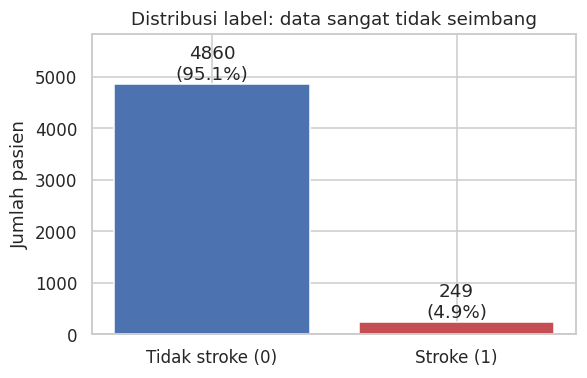

Base rate stroke = 4.87% -> model yang SELALU menebak "tidak stroke" sudah dapat akurasi 95.1%


In [8]:
counts = df[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5.5, 3.6))
bars = ax.bar(['Tidak stroke (0)', 'Stroke (1)'], counts.values, color=['#4C72B0', '#C44E52'])
for b_, v in zip(bars, counts.values):
    ax.text(b_.get_x() + b_.get_width() / 2, v, f'{v}\n({v / len(df):.1%})', ha='center', va='bottom')
ax.set_title('Distribusi label: data sangat tidak seimbang')
ax.set_ylabel('Jumlah pasien'); ax.set_ylim(0, counts.max() * 1.2)
plt.tight_layout(); plt.show()
BASE_RATE = df[TARGET].mean()
print(f'Base rate stroke = {BASE_RATE:.2%} -> model yang SELALU menebak "tidak stroke" sudah dapat akurasi {1 - BASE_RATE:.1%}')

**Insight 1 — Imbalance 95:5.** Akurasi menjadi metrik yang menyesatkan: model "bodoh" yang selalu menjawab *tidak stroke* sudah mendapat akurasi ≈95%. Konsekuensi: (a) split harus **stratified** agar data uji tetap punya ~5% kasus stroke, (b) evaluasi wajib memakai recall/precision/F-score, (c) model perlu penanganan imbalance.

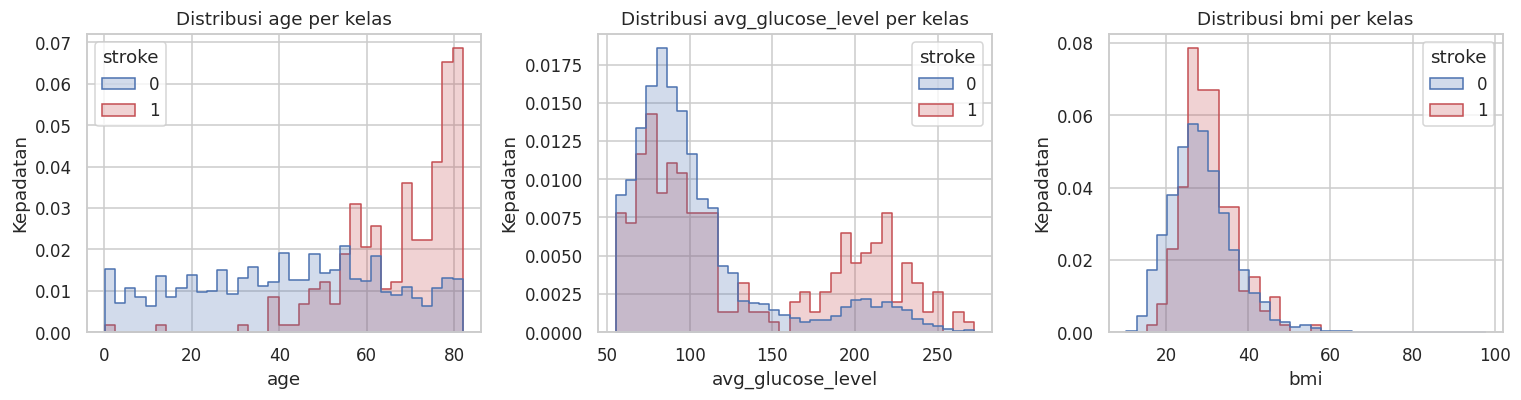

age        avg_glucose_level          bmi       
        mean median              mean median  mean median
stroke                                                   
0       42.0   43.0             104.8   91.5  28.8   28.0
1       67.7   71.0             132.5  105.2  30.5   29.7

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col in zip(axes, NUM_COLS):
    sns.histplot(data=df, x=col, hue=TARGET, stat='density', common_norm=False,
                 bins=35, element='step', palette=['#4C72B0', '#C44E52'], ax=ax)
    ax.set_title(f'Distribusi {col} per kelas'); ax.set_ylabel('Kepadatan')
plt.tight_layout(); plt.show()

display(df.groupby(TARGET)[NUM_COLS].agg(['mean', 'median']).round(1))

**Insight 2 — Usia adalah pembeda terkuat.** Median usia pasien stroke ≈ 71 tahun vs ≈ 43 tahun. Hampir tidak ada kasus stroke di bawah 30 tahun.

**Insight 3 — Glukosa bimodal.** Distribusi `avg_glucose_level` punya dua puncak (~90 dan ~200 mg/dL); pasien stroke lebih banyak di puncak kedua (rata-rata 132 vs 105). Ini cocok dengan kelompok penderita diabetes.

**Insight 4 — BMI hanya sedikit berbeda** (rata-rata 30,5 vs 28,8). Kontribusinya ke model kemungkinan kecil.

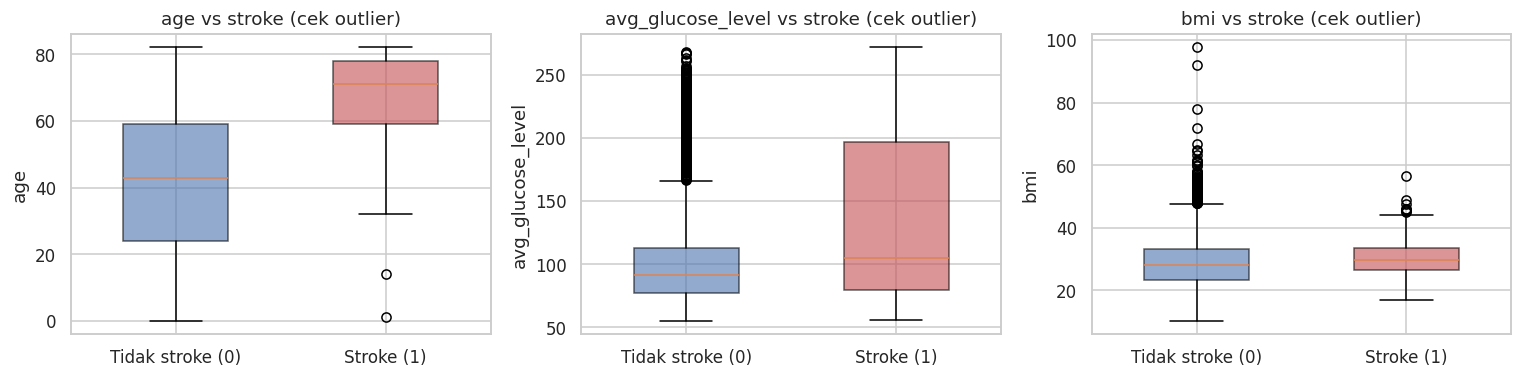

{'age': 0, 'avg_glucose_level': 627, 'bmi': 110}


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, col in zip(axes, NUM_COLS):
    bp = ax.boxplot([df.loc[df[TARGET] == k, col].dropna() for k in (0, 1)], patch_artist=True, widths=0.5)
    for patch, warna in zip(bp['boxes'], ['#4C72B0', '#C44E52']):
        patch.set_facecolor(warna); patch.set_alpha(0.6)
    ax.set_xticks([1, 2]); ax.set_xticklabels(['Tidak stroke (0)', 'Stroke (1)'])
    ax.set_title(f'{col} vs stroke (cek outlier)'); ax.set_ylabel(col)
plt.tight_layout(); plt.show()

def iqr_outlier(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()
print({c: int(iqr_outlier(df[c].dropna())) for c in NUM_COLS})

**Catatan outlier.** Aturan IQR menandai ~600 nilai glukosa sebagai outlier — tetapi itu adalah **puncak kedua yang nyata** (penderita diabetes), bukan kesalahan data. Karena itu saya **tidak** membuang outlier berdasarkan IQR; saya hanya membatasi nilai paling ekstrem (persentil 1–99) agar tidak mendominasi gradient.

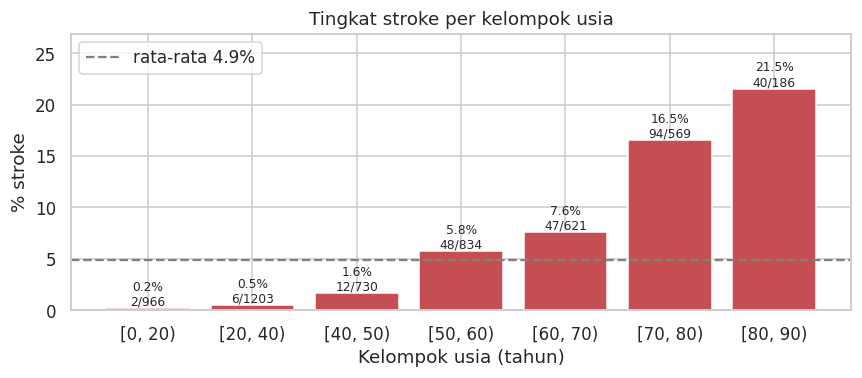

In [11]:
bins = [0, 20, 40, 50, 60, 70, 80, 90]
grp = pd.cut(df['age'], bins=bins, right=False)
tab = df.groupby(grp, observed=True)[TARGET].agg(['mean', 'sum', 'count'])
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(tab.index.astype(str), tab['mean'] * 100, color='#C44E52')
for i, (m, s, n) in enumerate(tab.values):
    ax.text(i, m * 100, f'{m:.1%}\n{int(s)}/{int(n)}', ha='center', va='bottom', fontsize=8)
ax.axhline(BASE_RATE * 100, ls='--', c='gray', label=f'rata-rata {BASE_RATE:.1%}')
ax.set_title('Tingkat stroke per kelompok usia'); ax.set_xlabel('Kelompok usia (tahun)')
ax.set_ylabel('% stroke'); ax.set_ylim(0, tab['mean'].max() * 125); ax.legend()
plt.tight_layout(); plt.show()

**Insight 5 — Risiko naik tajam dan tidak linear terhadap usia**: <1% di bawah 40 tahun → ±7% di usia 60-an → ±20% di usia 80+. Logistic regression memodelkan hubungan ini sebagai kenaikan *log-odds* yang linear terhadap usia, yang cukup cocok dengan pola eksponensial seperti ini.

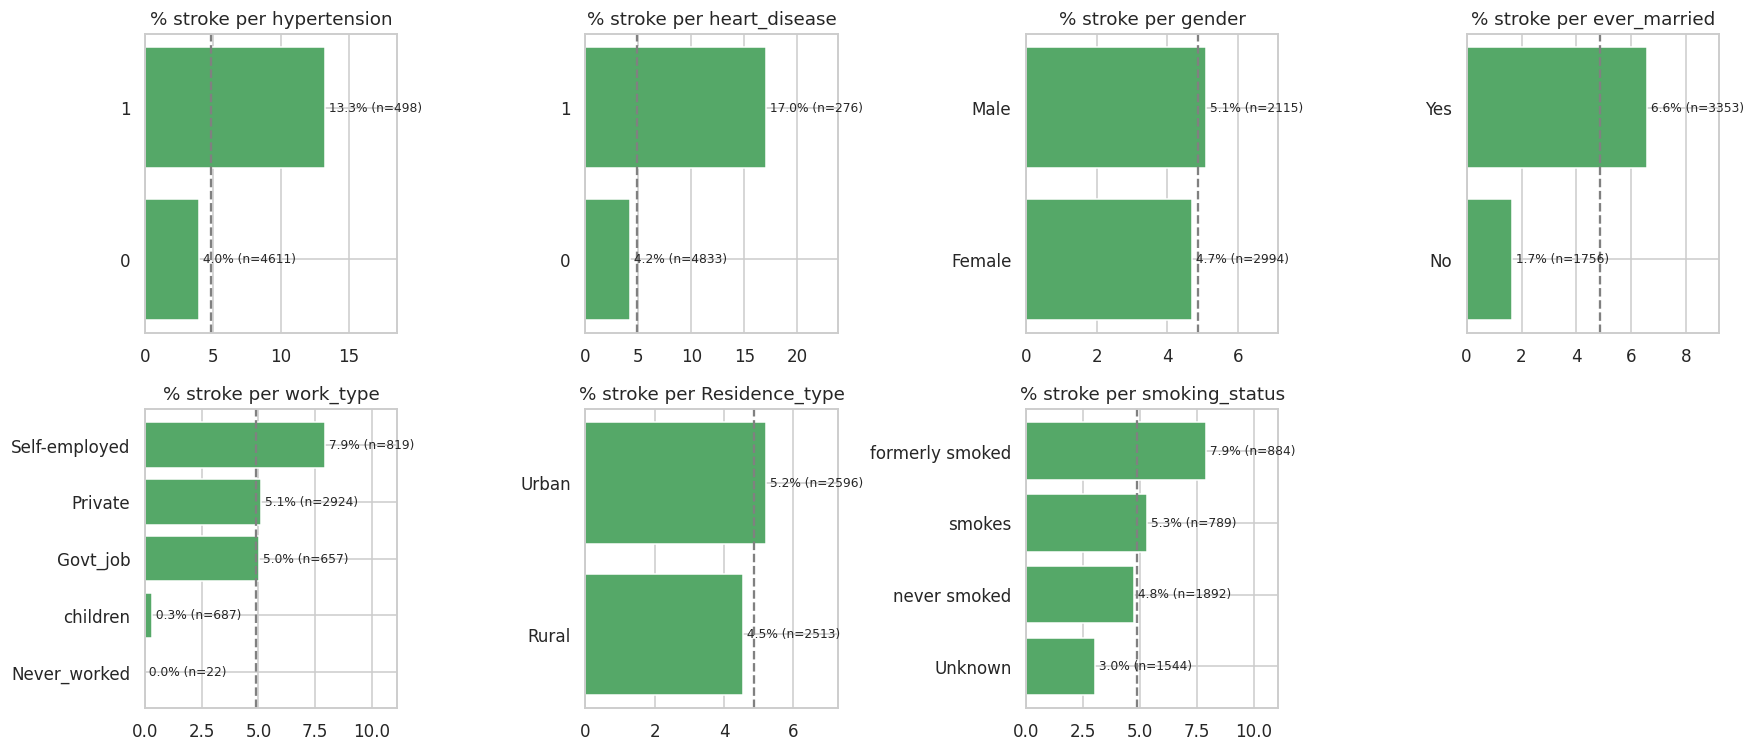

In [12]:
cols_rate = BIN_COLS + CAT_COLS
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), cols_rate):
    t = df.groupby(col)[TARGET].agg(['mean', 'count']).sort_values('mean')
    ax.barh(t.index.astype(str), t['mean'] * 100, color='#55A868')
    for i, (m, n) in enumerate(t.values):
        ax.text(m * 100, i, f' {m:.1%} (n={int(n)})', va='center', fontsize=8)
    ax.axvline(BASE_RATE * 100, ls='--', c='gray')
    ax.set_title(f'% stroke per {col}'); ax.set_xlim(0, t['mean'].max() * 140)
axes.ravel()[-1].axis('off')
plt.tight_layout(); plt.show()

**Insight 6 — Riwayat penyakit memperbesar risiko.** Tingkat stroke: hipertensi 13,3% vs 4,0% (≈3,3×), penyakit jantung 17,0% vs 4,2% (≈4×).
⚠️ Hati-hati membaca: **bukan** berarti "penderita stroke rata-rata punya penyakit jantung" — hanya 18,9% pasien stroke yang punya penyakit jantung. Yang benar: *orang dengan penyakit jantung punya risiko stroke ±4× lebih tinggi*.

**Insight 7 — Confounding oleh usia.** `ever_married=Yes` (6,6% vs 1,7%) dan `work_type=Self-employed` terlihat berisiko, tetapi kelompok ini rata-rata lebih tua. Menikah tidak menyebabkan stroke; ini efek usia yang "menumpang". Korelasi ≠ sebab-akibat.

**Insight 8 — Residence_type dan gender hampir tidak berpengaruh** (selisih < 1 poin persen).

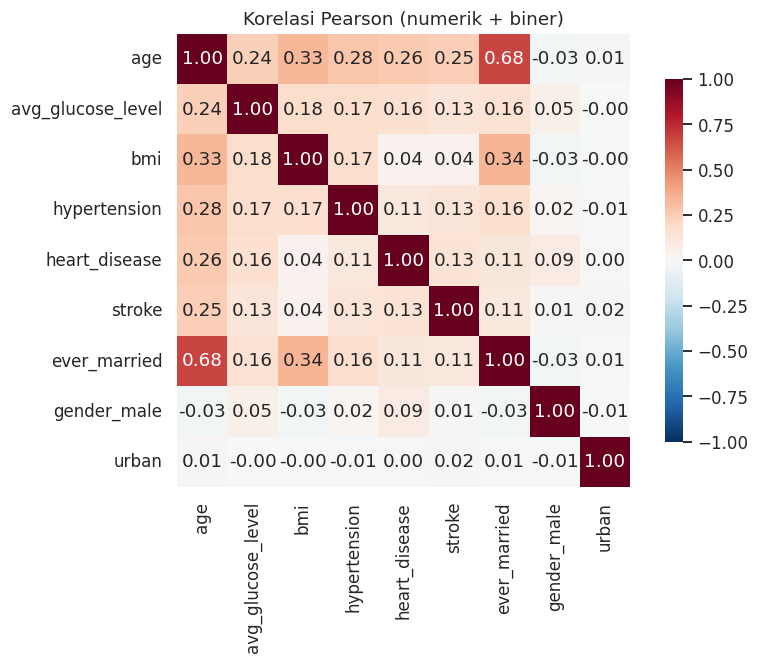

Korelasi dengan stroke (urut):
age                  0.245
heart_disease        0.135
avg_glucose_level    0.132
hypertension         0.128
ever_married         0.108
bmi                  0.042
urban                0.015
gender_male          0.009
Name: stroke, dtype: float64


In [13]:
df_corr = df[NUM_COLS + BIN_COLS + [TARGET]].copy()
df_corr['ever_married'] = (df['ever_married'] == 'Yes').astype(int)
df_corr['gender_male'] = (df['gender'] == 'Male').astype(int)
df_corr['urban'] = (df['Residence_type'] == 'Urban').astype(int)
corr = df_corr.corr()
plt.figure(figsize=(8, 6.2))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True, cbar_kws={'shrink': .8})
plt.title('Korelasi Pearson (numerik + biner)')
plt.tight_layout(); plt.show()
print('Korelasi dengan stroke (urut):'); print(corr[TARGET].drop(TARGET).sort_values(ascending=False).round(3))

**Insight 9 — Korelasi linear dengan label lemah** (tertinggi `age` 0,25). Wajar untuk label yang jarang (5%). Korelasi `age`–`ever_married` 0,68 menguatkan Insight 7. Tidak ada pasangan fitur dengan korelasi ekstrem (>0,9), jadi tidak ada fitur yang wajib dibuang karena redundansi.

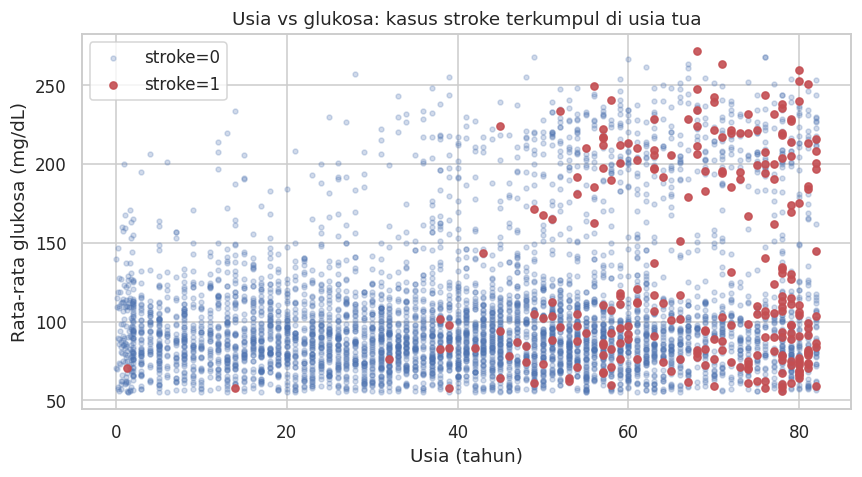

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for lab, c, a, s in [(0, '#4C72B0', .25, 10), (1, '#C44E52', .9, 22)]:
    d = df[df[TARGET] == lab]
    ax.scatter(d['age'], d['avg_glucose_level'], s=s, alpha=a, c=c, label=f'stroke={lab}')
ax.set_xlabel('Usia (tahun)'); ax.set_ylabel('Rata-rata glukosa (mg/dL)')
ax.set_title('Usia vs glukosa: kasus stroke terkumpul di usia tua'); ax.legend()
plt.tight_layout(); plt.show()

**Insight 10 — Kelas tidak terpisah dengan jelas.** Bahkan di usia >60 dan glukosa tinggi, mayoritas tetap *tidak stroke*. Ekspektasi realistis: model akan bisa menangkap sebagian besar kasus stroke (recall tinggi) tetapi dengan cukup banyak *false alarm* (precision rendah). Ini batas informasi data, bukan semata kelemahan model.

### Ringkasan EDA → implikasi untuk pemodelan
| Insight | Implikasi |
|---|---|
| Imbalance 95:5 | split stratified; metrik recall/F; class weight; tuning threshold |
| Usia, hipertensi, penyakit jantung, glukosa = sinyal utama | fitur ini dipertahankan; koefisiennya dicek apakah positif |
| Missing BMI tidak acak | uji fitur `bmi_missing` di Modul C, tetapi waspadai kebocoran proses pengumpulan data |
| Outlier BMI & glukosa bimodal | clipping persentil (bukan buang baris) + z-score |
| Confounding usia | tidak menyimpulkan sebab-akibat dari koefisien |

In [15]:
df.to_csv('df_clean.csv', index=False)
print('Tersimpan df_clean.csv:', df.shape)

Tersimpan df_clean.csv: (5109, 11)


---
# Modul B — Klasifikasi (Logistic Regression dari nol)
Urutan yang **wajib** dijaga agar tidak ada kebocoran data:
`split → fit preprocessing di TRAIN → transform train & test dengan parameter yang sama → latih model di TRAIN`.

In [16]:
df = pd.read_csv('df_clean.csv')
y_all = df[TARGET].values
print(df.shape, '| positif:', y_all.sum())

(5109, 11) | positif: 249


## B.1 Pembagian data latih & uji (manual, stratified)
**Rasio 80:20.** Dengan ±5.100 baris, 20% data uji = ±1.020 baris dengan ±50 kasus stroke — cukup untuk menghitung recall secara bermakna, sementara 80% data latih menyisakan ±200 kasus stroke untuk belajar. Rasio 70:30 akan mengurangi kasus stroke di data latih; 90:10 membuat data uji hanya ±25 kasus stroke (metrik jadi tidak stabil).

**Kenapa diacak?** Data asli tersusun berurutan — semua kasus stroke ada di baris awal. Tanpa diacak, data uji bisa tidak berisi kasus stroke sama sekali.

**Kenapa stratified?** Pengacakan biasa bisa saja membuat proporsi stroke di data uji meleset (misal 3% atau 7%). Stratified mengacak *di dalam setiap kelas* sehingga proporsi 95:5 terjaga di train dan test.

In [17]:
def stratified_split(y, test_frac=0.2, seed=SEED):
    rng = np.random.default_rng(seed)
    train_idx, test_idx = [], []
    for kelas in np.unique(y):
        idx = rng.permutation(np.where(y == kelas)[0])   # acak di dalam kelas
        n_test = int(round(len(idx) * test_frac))
        test_idx.extend(idx[:n_test]); train_idx.extend(idx[n_test:])
    return rng.permutation(train_idx), rng.permutation(test_idx)

train_idx, test_idx = stratified_split(y_all, 0.2)
df_train, df_test = df.iloc[train_idx].reset_index(drop=True), df.iloc[test_idx].reset_index(drop=True)
y_train, y_test = df_train[TARGET].values, df_test[TARGET].values

assert len(set(train_idx) & set(test_idx)) == 0 and len(train_idx) + len(test_idx) == len(df)
print(pd.DataFrame({'baris': [len(df), len(df_train), len(df_test)],
                    'kasus_stroke': [y_all.sum(), y_train.sum(), y_test.sum()],
                    '%_stroke': [y_all.mean() * 100, y_train.mean() * 100, y_test.mean() * 100]},
                   index=['semua', 'train', 'test']).round(2))

       baris  kasus_stroke  %_stroke
semua   5109           249      4.87
train   4087           199      4.87
test    1022            50      4.89


## B.2 Preprocessing (fit di data latih saja)
| Langkah | Kolom | Cara | Parameter dihitung dari |
|---|---|---|---|
| Imputasi | `bmi` | median | train |
| Clipping | numerik | persentil 1 & 99 | train |
| Standarisasi (z-score) | numerik | $z = (x-\mu)/\sigma$ | train |
| One-hot encoding | kategorikal | kategori pertama = referensi (dibuang, menghindari *dummy trap*) | daftar kategori train |
| Biner | `hypertension`, `heart_disease` | tetap 0/1 | – |

**Kenapa normalisasi?** Gradient descent memakai satu learning rate untuk semua bobot. Jika `avg_glucose_level` (skala ratusan) bercampur dengan biner (0/1), gradient bobot glukosa jauh lebih besar sehingga training berzig-zag dan lambat. Z-score menyamakan skala → konvergen lebih cepat dan stabil, serta koefisien bisa dibandingkan.
**Kenapa z-score bukan min-max?** Min-max sangat sensitif terhadap nilai maksimum (BMI 97,6 akan menekan semua nilai lain ke rentang sempit). Z-score lebih tahan, apalagi setelah clipping.
**Kenapa fit di train saja?** Jika mean/std/median dihitung dari seluruh data, informasi data uji ikut masuk ke model (*data leakage*) → skor uji terlalu optimis. Data uji harus diperlakukan seperti data baru dari dunia nyata.

In [18]:
class Preprocessor:
    # Menyimpan semua parameter preprocessing agar bisa dipakai ulang di GUI (Modul D)
    def __init__(self, use_missing_flag=False):
        self.use_missing_flag = use_missing_flag

    def fit(self, d):
        self.impute = {c: float(d[c].median()) for c in NUM_COLS}
        filled = d[NUM_COLS].fillna(self.impute)
        self.clip = {c: [float(filled[c].quantile(.01)), float(filled[c].quantile(.99))] for c in NUM_COLS}
        clipped = pd.DataFrame({c: filled[c].clip(*self.clip[c]) for c in NUM_COLS})
        self.scale = {c: [float(clipped[c].mean()), float(clipped[c].std(ddof=0))] for c in NUM_COLS}
        # urutkan kategori: kategori pertama (alfabet) dijadikan referensi
        self.cats = {c: sorted(d[c].unique().tolist()) for c in CAT_COLS}
        self.feature_names = (NUM_COLS + BIN_COLS + (['bmi_missing'] if self.use_missing_flag else [])
                              + [f'{c}={k}' for c in CAT_COLS for k in self.cats[c][1:]])
        return self

    def transform(self, d):
        cols = []
        for c in NUM_COLS:
            v = d[c].fillna(self.impute[c]).clip(*self.clip[c])
            cols.append(((v - self.scale[c][0]) / self.scale[c][1]).values)
        for c in BIN_COLS:
            cols.append(d[c].values.astype(float))
        if self.use_missing_flag:
            cols.append(d['bmi'].isna().values.astype(float))
        for c in CAT_COLS:
            for k in self.cats[c][1:]:
                cols.append((d[c] == k).values.astype(float))   # kategori baru -> semua 0 (aman)
        X = np.column_stack(cols)
        assert not np.isnan(X).any(), 'Masih ada NaN setelah preprocessing'
        return X

    def to_dict(self):
        return {'numeric_cols': NUM_COLS, 'binary_cols': BIN_COLS, 'categorical_cols': self.cats,
                'impute': self.impute, 'clip': self.clip, 'scale': self.scale,
                'use_missing_flag': self.use_missing_flag, 'feature_names': self.feature_names}

prep = Preprocessor().fit(df_train)
X_train, X_test = prep.transform(df_train), prep.transform(df_test)
print('X_train', X_train.shape, '| X_test', X_test.shape)
print('Fitur:', prep.feature_names)
print('Median bmi (train):', round(prep.impute['bmi'], 2), '| clip bmi:', [round(v, 1) for v in prep.clip['bmi']])
print('Cek z-score di train -> mean', X_train[:, :3].mean(0).round(3), 'std', X_train[:, :3].std(0).round(3))

X_train (4087, 15) | X_test (1022, 15)
Fitur: ['age', 'avg_glucose_level', 'bmi', 'hypertension', 'heart_disease', 'gender=Male', 'ever_married=Yes', 'work_type=Never_worked', 'work_type=Private', 'work_type=Self-employed', 'work_type=children', 'Residence_type=Urban', 'smoking_status=formerly smoked', 'smoking_status=never smoked', 'smoking_status=smokes']
Median bmi (train): 28.0 | clip bmi: [15.2, 52.8]
Cek z-score di train -> mean [0. 0. 0.] std [1. 1. 1.]


## B.3 Model: rumus dan cara kerja
**1. Skor linear** untuk satu pasien dengan fitur $\mathbf{x}$: $\; z = \mathbf{w}^\top\mathbf{x} + b$

**2. Sigmoid** mengubah skor menjadi peluang di rentang (0, 1): $\; \hat y = \sigma(z) = \dfrac{1}{1+e^{-z}}$.
Interpretasi: $z$ adalah *log-odds*, $\;\log\dfrac{\hat y}{1-\hat y} = z$. Setiap kenaikan 1 unit fitur $x_j$ mengalikan odds dengan $e^{w_j}$.

**3. Loss: Binary Cross-Entropy (BCE)** — rata-rata dari $N$ sampel, dengan bobot sampel $s_i$ (=1 jika tanpa class weight):
$$L = -\frac{1}{N}\sum_{i=1}^{N} s_i\Big[y_i\log\hat y_i + (1-y_i)\log(1-\hat y_i)\Big] + \frac{\lambda}{2}\lVert\mathbf w\rVert^2$$
BCE menghukum keras prediksi yang yakin tapi salah (misal $\hat y=0{,}01$ padahal $y=1$ → $-\log 0{,}01 = 4{,}6$). $\hat y$ di-*clip* ke $[10^{-12}, 1-10^{-12}]$ agar tidak terjadi $\log 0$.

**4. Gradient.** Karena $\sigma'(z) = \sigma(z)(1-\sigma(z))$, turunan BCE menyederhana menjadi:
$$\frac{\partial L}{\partial \mathbf w} = \frac{1}{N}X^\top\big(s\odot(\hat y - y)\big) + \lambda\mathbf w, \qquad \frac{\partial L}{\partial b} = \frac{1}{N}\sum_i s_i(\hat y_i - y_i)$$

**5. Gradient descent:** $\;\mathbf w \leftarrow \mathbf w - \eta\,\nabla_{\mathbf w}L,\;\; b \leftarrow b - \eta\,\partial L/\partial b$

**6. Class weight** (untuk Modul C): $s_i = \dfrac{N}{2N_{c}}$ — kelas langka (stroke) mendapat bobot ±10, kelas mayoritas ±0,5, sehingga kedua kelas berkontribusi sama besar ke loss.

**7. Prediksi kelas:** $\hat y \ge t \Rightarrow$ stroke. Ambang $t$ default 0,5 tetapi bisa diatur (Modul C).

In [19]:
class LogisticRegressionScratch:
    def __init__(self, lr=0.3, epochs=3000, l2=0.0, class_weight=False, threshold=0.5):
        self.lr, self.epochs, self.l2 = lr, epochs, l2
        self.class_weight, self.threshold = class_weight, threshold

    @staticmethod
    def sigmoid(z):
        return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))   # clip -> tidak overflow

    def _sample_weight(self, y):
        if not self.class_weight:
            return np.ones(len(y)), 1.0
        n, n_pos = len(y), y.sum()
        w_pos, w_neg = n / (2 * n_pos), n / (2 * (n - n_pos))
        return np.where(y == 1, w_pos, w_neg), w_pos / w_neg

    def loss(self, X, y, w=None, b=None, s=None):
        w = self.w if w is None else w; b = self.b if b is None else b
        s = np.ones(len(y)) if s is None else s
        p = np.clip(self.sigmoid(X @ w + b), 1e-12, 1 - 1e-12)
        bce = -np.mean(s * (y * np.log(p) + (1 - y) * np.log(1 - p)))
        return bce + 0.5 * self.l2 * np.sum(w ** 2)

    def gradients(self, X, y, w, b, s):
        err = s * (self.sigmoid(X @ w + b) - y)
        return X.T @ err / len(y) + self.l2 * w, err.mean()

    def fit(self, X, y):
        self.w, self.b = np.zeros(X.shape[1]), 0.0
        s, self.class_weight_ratio = self._sample_weight(y)
        self.loss_history = []
        for _ in range(self.epochs):
            self.loss_history.append(self.loss(X, y, s=s))   # catat loss SEBELUM update
            gw, gb = self.gradients(X, y, self.w, self.b, s)
            self.w -= self.lr * gw
            self.b -= self.lr * gb
        self.loss_history.append(self.loss(X, y, s=s))
        return self

    def predict_proba(self, X):
        return self.sigmoid(X @ self.w + self.b)

    def predict(self, X, threshold=None):
        t = self.threshold if threshold is None else threshold
        return (self.predict_proba(X) >= t).astype(int)

## B.4 Bukti bahwa training berjalan benar
Tiga bukti: **(1) gradient check** — gradient rumus dibandingkan dengan gradient numerik (beda hingga), **(2) loss turun dan stabil**, **(3) arah koefisien masuk akal** sesuai EDA.

In [20]:
# (1) Gradient check: dL/dw_j ~ [L(w + eps*e_j) - L(w - eps*e_j)] / (2*eps)
gc = LogisticRegressionScratch(l2=0.01, class_weight=True)
s_gc, _ = gc._sample_weight(y_train)
rng = np.random.default_rng(SEED)
w0, b0 = rng.normal(0, 0.1, X_train.shape[1]), 0.1
gw, gb = gc.gradients(X_train, y_train, w0, b0, s_gc)
eps, num = 1e-5, np.zeros_like(w0)
for j in range(len(w0)):
    e = np.zeros_like(w0); e[j] = eps
    num[j] = (gc.loss(X_train, y_train, w0 + e, b0, s_gc) - gc.loss(X_train, y_train, w0 - e, b0, s_gc)) / (2 * eps)
rel_err = np.linalg.norm(gw - num) / np.linalg.norm(gw + num)
print(f'Relative error gradient analitik vs numerik: {rel_err:.2e}  (< 1e-6 berarti rumus gradient benar)')
assert rel_err < 1e-6

Relative error gradient analitik vs numerik: 3.46e-11  (< 1e-6 berarti rumus gradient benar)


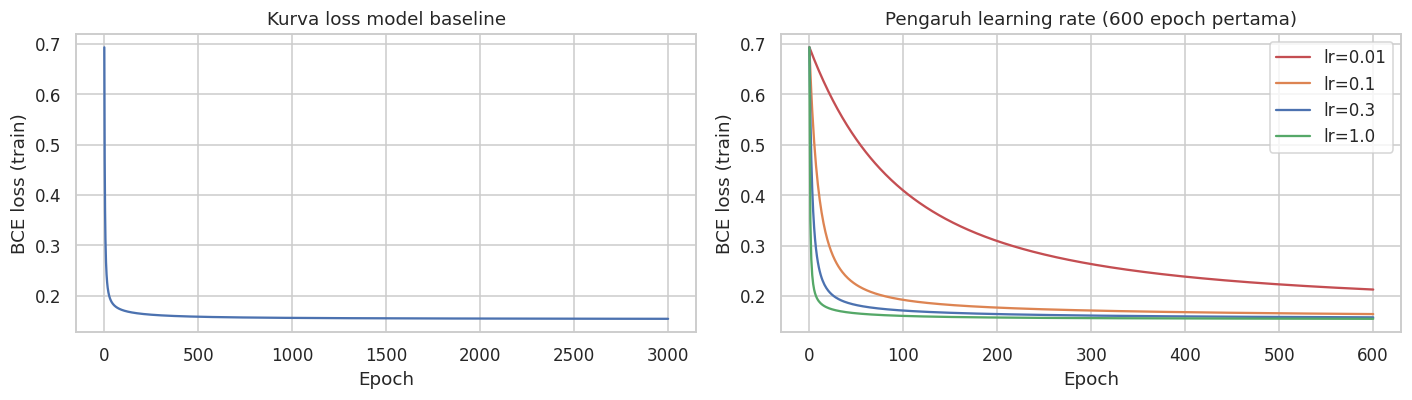

Loss awal 0.6931 (≈ ln 2 = 0.6931 karena w=0 -> semua prediksi 0,5) | loss akhir 0.1545
Penurunan 500 epoch terakhir: 1.85e-04 -> sudah konvergen
Loss selalu turun (monoton): True


In [21]:
# (2) Model baseline: tanpa penanganan imbalance, ambang 0,5
model_0 = LogisticRegressionScratch(lr=0.3, epochs=3000).fit(X_train, y_train)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(model_0.loss_history, c='#4C72B0')
axes[0].set_title('Kurva loss model baseline'); axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('BCE loss (train)')
for lr, c in [(0.01, '#C44E52'), (0.1, '#DD8452'), (0.3, '#4C72B0'), (1.0, '#55A868')]:
    h = LogisticRegressionScratch(lr=lr, epochs=600).fit(X_train, y_train).loss_history
    axes[1].plot(h, label=f'lr={lr}', c=c)
axes[1].set_title('Pengaruh learning rate (600 epoch pertama)'); axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('BCE loss (train)'); axes[1].legend()
plt.tight_layout(); plt.show()

h = model_0.loss_history
print(f'Loss awal {h[0]:.4f} (≈ ln 2 = 0.6931 karena w=0 -> semua prediksi 0,5) | loss akhir {h[-1]:.4f}')
print(f'Penurunan 500 epoch terakhir: {h[-500] - h[-1]:.2e} -> sudah konvergen')
print('Loss selalu turun (monoton):', bool(np.all(np.diff(h) <= 1e-12)))

In [22]:
# (3) Koefisien: arah & besar efek
coef = pd.DataFrame({'fitur': prep.feature_names, 'bobot': model_0.w,
                     'odds_ratio (e^w)': np.exp(model_0.w)}).sort_values('bobot', ascending=False)
display(coef.round(3).reset_index(drop=True))

,fitur,bobot,odds_ratio (e^w)
0,age,1.627,5.090
1,hypertension,0.518,1.679
2,avg_glucose_level,0.198,1.219
3,heart_disease,0.186,1.205
4,bmi,0.041,1.042
5,Residence_type=Urban,0.039,1.040
6,smoking_status=formerly smoked,0.038,1.039
7,smoking_status=smokes,0.022,1.022
8,gender=Male,0.014,1.014
9,work_type=Never_worked,-0.038,0.963


**Interpretasi.** Bobot terbesar ada pada `age` (odds ×≈5 untuk setiap kenaikan 1 standar deviasi usia ≈ 22,6 tahun), diikuti `hypertension`, `avg_glucose_level`, dan `heart_disease` — keempatnya positif, sesuai insight EDA. Ini bukti tambahan bahwa model belajar pola yang masuk akal, bukan noise.

**Bukti confounding (Insight 7):** di EDA, `ever_married=Yes` dan `work_type=Self-employed` punya tingkat stroke tinggi, tetapi di sini bobotnya **negatif**. Setelah usia sudah diperhitungkan oleh model, efek "menikah" dan "wiraswasta" hilang bahkan berbalik — tingginya tingkat stroke di EDA memang karena kelompok itu lebih tua (rata-rata usia wiraswasta 60 tahun vs 45 untuk swasta). Karena fitur saling berkorelasi, koefisien tidak boleh dibaca sebagai sebab-akibat.

---
# Modul C — Evaluasi Model
## C.1 Confusion matrix & metrik (tanpa library)
| | Prediksi 0 | Prediksi 1 |
|---|---|---|
| **Aktual 0** | TN | FP (*false alarm*) |
| **Aktual 1** | FN (**stroke terlewat**) | TP |

$\text{Precision} = \frac{TP}{TP+FP}$, $\;\text{Recall} = \frac{TP}{TP+FN}$, $\;F_\beta = \frac{(1+\beta^2)\,P\,R}{\beta^2P + R}$ ($F_1$ untuk $\beta=1$; $F_2$ memberi bobot recall 2× precision), $\;\text{Balanced acc} = \frac{\text{Recall}+\text{Specificity}}{2}$.
ROC-AUC dihitung dengan rumus peringkat (Mann–Whitney): peluang bahwa pasien stroke acak mendapat skor lebih tinggi daripada pasien non-stroke acak — tidak bergantung pada ambang.

In [23]:
def confusion(y_true, y_pred):
    tp = int(np.sum((y_true == 1) & (y_pred == 1))); tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1))); fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    return np.array([[tn, fp], [fn, tp]])

def safe_div(a, b):
    return a / b if b > 0 else 0.0

def fbeta(p, r, beta):
    return safe_div((1 + beta ** 2) * p * r, beta ** 2 * p + r)

def roc_auc(y_true, score):
    order = np.argsort(score)
    ranks = np.empty(len(score)); ranks[order] = np.arange(1, len(score) + 1)
    for s in np.unique(score):                       # nilai kembar -> rata-rata peringkat
        m = score == s
        if m.sum() > 1: ranks[m] = ranks[m].mean()
    n_pos = y_true.sum(); n_neg = len(y_true) - n_pos
    return (ranks[y_true == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)

def metrics(y_true, y_pred, score=None):
    (tn, fp), (fn, tp) = confusion(y_true, y_pred)
    p, r, spec = safe_div(tp, tp + fp), safe_div(tp, tp + fn), safe_div(tn, tn + fp)
    out = {'accuracy': (tp + tn) / len(y_true), 'precision': p, 'recall': r, 'specificity': spec,
           'f1': fbeta(p, r, 1), 'f2': fbeta(p, r, 2), 'balanced_acc': (r + spec) / 2,
           'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn}
    if score is not None:
        out['roc_auc'] = roc_auc(y_true, score)
    return out

def plot_cm(cm, title, ax):
    lab = np.array([[f'TN\n{cm[0,0]}', f'FP\n{cm[0,1]}'], [f'FN\n{cm[1,0]}', f'TP\n{cm[1,1]}']])
    sns.heatmap(cm, annot=lab, fmt='', cmap='Blues', cbar=False, ax=ax, annot_kws={'size': 12})
    ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual'); ax.set_title(title)
    ax.set_xticklabels(['Tidak stroke', 'Stroke']); ax.set_yticklabels(['Tidak stroke', 'Stroke'], rotation=0)

# Uji fungsi metrik dengan contoh yang bisa dihitung manual
yt, yp = np.array([1, 1, 1, 0, 0, 0, 0, 0]), np.array([1, 1, 0, 1, 0, 0, 0, 0])
m = metrics(yt, yp)
assert (m['TP'], m['FP'], m['FN'], m['TN']) == (2, 1, 1, 4) and abs(m['precision'] - 2/3) < 1e-12
assert abs(roc_auc(np.array([0, 0, 1, 1]), np.array([.1, .4, .35, .8])) - 0.75) < 1e-12
print('Fungsi metrik lolos uji manual.')

Fungsi metrik lolos uji manual.


## C.2 Metrik apa yang dipakai, dan kenapa
Kasusnya **skrining risiko stroke**. Dua jenis kesalahan tidak sama mahalnya:
- **FN** (pasien berisiko dibilang aman) → pasien tidak periksa lanjut; akibatnya bisa fatal.
- **FP** (pasien aman dibilang berisiko) → biaya pemeriksaan tambahan; merepotkan tetapi tidak fatal.

Maka **recall adalah prioritas**, tetapi precision tidak boleh diabaikan (kalau semua orang dibilang berisiko, recall 100% tapi alatnya tidak berguna).
→ Metrik utama: **F2-score** (recall dianggap 2× lebih penting). Dilaporkan juga: recall, precision, F1, balanced accuracy, ROC-AUC.
→ **Accuracy tidak dipakai untuk memilih model** karena model yang selalu menebak "tidak stroke" sudah 95%.

In [24]:
res_0 = metrics(y_test, model_0.predict(X_test), model_0.predict_proba(X_test))
dummy = metrics(y_test, np.zeros_like(y_test))
print(pd.DataFrame([res_0, dummy], index=['Model 0 (baseline, t=0.5)', 'Dummy: selalu "tidak stroke"'])
      [['accuracy', 'precision', 'recall', 'f1', 'f2', 'roc_auc', 'TP', 'FP', 'FN', 'TN']].round(3))
print('\nMax probabilitas yang dihasilkan model 0 di data uji:', model_0.predict_proba(X_test).max().round(3))

                              accuracy  precision  recall   f1   f2  roc_auc  \
Model 0 (baseline, t=0.5)        0.950        0.0     0.0  0.0  0.0    0.835   
Dummy: selalu "tidak stroke"     0.951        0.0     0.0  0.0  0.0      NaN   

                              TP  FP  FN   TN  
Model 0 (baseline, t=0.5)      0   1  50  971  
Dummy: selalu "tidak stroke"   0   0  50  972  

Max probabilitas yang dihasilkan model 0 di data uji: 0.52


**Analisis baseline.** Model 0 punya accuracy ±95% — **sama dengan model dummy**. Recall = 0: tidak ada satu pun pasien stroke yang terdeteksi; hanya 1 pasien yang diprediksi stroke dan itu pun salah (FP). Probabilitas yang dikeluarkan model hampir selalu di bawah 0,5. Padahal ROC-AUC ±0,84 menunjukkan model **sebenarnya bisa mengurutkan risiko dengan baik** — masalahnya ada di (1) loss yang didominasi kelas mayoritas dan (2) ambang 0,5 yang tidak cocok untuk base rate 5%.

## C.3 Perbaikan model — dipilih dengan 5-fold cross-validation di data latih
Data uji **tidak boleh** dipakai untuk memilih ambang atau hyperparameter (itu sama saja bocor). Jadi semua pilihan dibuat dengan *stratified 5-fold CV* di data latih: setiap baris train mendapat prediksi *out-of-fold* dari model yang tidak pernah melihatnya. Preprocessing juga di-fit ulang di setiap fold.

| Skenario | Perubahan |
|---|---|
| S0 | baseline: tanpa class weight, t = 0,5 |
| S1 | + class weight, t = 0,5 |
| S2 | + class weight + ambang optimal (maks F2 pada prediksi out-of-fold) |
| S3 | S2 + regularisasi L2 (λ = 0,01) |
| S4 | S2 + fitur `bmi_missing` |

In [25]:
def stratified_kfold(y, k=5, seed=SEED):
    rng = np.random.default_rng(seed)
    folds = [[] for _ in range(k)]
    for kelas in np.unique(y):
        idx = rng.permutation(np.where(y == kelas)[0])
        for i, chunk in enumerate(np.array_split(idx, k)):
            folds[i].extend(chunk)
    return [np.array(f) for f in folds]

def oof_scores(d, y, model_kwargs, use_flag=False, k=5):
    oof = np.zeros(len(y))
    for f in stratified_kfold(y, k):
        tr = np.setdiff1d(np.arange(len(y)), f)
        p = Preprocessor(use_flag).fit(d.iloc[tr])               # fit ulang per fold -> tanpa bocor
        m = LogisticRegressionScratch(**model_kwargs).fit(p.transform(d.iloc[tr]), y[tr])
        oof[f] = m.predict_proba(p.transform(d.iloc[f]))
    return oof

THRESHOLDS = np.round(np.arange(0.05, 0.96, 0.01), 2)
def best_threshold(y, score, beta=2):
    vals = [fbeta(metrics(y, (score >= t).astype(int))['precision'],
                  metrics(y, (score >= t).astype(int))['recall'], beta) for t in THRESHOLDS]
    return float(THRESHOLDS[int(np.argmax(vals))]), vals

scenarios = {
    'S0 baseline':             (dict(), False, 'fixed'),
    'S1 +class weight':        (dict(class_weight=True), False, 'fixed'),
    'S2 +cw +threshold':       (dict(class_weight=True), False, 'tuned'),
    'S3 +cw +thr +L2':         (dict(class_weight=True, l2=0.01), False, 'tuned'),
    'S4 +cw +thr +bmi_missing':(dict(class_weight=True), True, 'tuned'),
}
rows, oof_store = [], {}
for name, (kw, flag, mode) in scenarios.items():
    oof = oof_scores(df_train, y_train, kw, flag)
    t = best_threshold(y_train, oof)[0] if mode == 'tuned' else 0.5
    r = metrics(y_train, (oof >= t).astype(int), oof); r['threshold'] = t
    rows.append(pd.Series(r, name=name)); oof_store[name] = oof
cv_table = pd.DataFrame(rows)[['threshold', 'recall', 'precision', 'f1', 'f2', 'balanced_acc', 'roc_auc', 'accuracy']]
cv_table.round(3)

,threshold,recall,precision,f1,f2,balanced_acc,roc_auc,accuracy
S0 baseline,0.50,0.005,0.500,0.010,0.006,0.502,0.840,0.951
S1 +class weight,0.50,0.799,0.135,0.231,0.403,0.768,0.839,0.741
S2 +cw +threshold,0.62,0.704,0.161,0.262,0.420,0.758,0.839,0.807
S3 +cw +thr +L2,0.63,0.698,0.170,0.273,0.431,0.762,0.841,0.819
S4 +cw +thr +bmi_missing,0.65,0.673,0.176,0.279,0.430,0.756,0.850,0.831


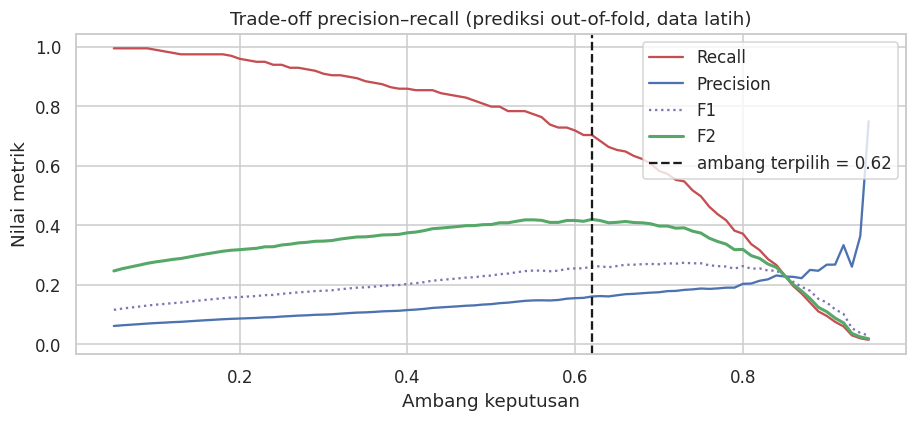

In [26]:
oof = oof_store['S2 +cw +threshold']
t_best, f2_vals = best_threshold(y_train, oof)
P = [metrics(y_train, (oof >= t).astype(int))['precision'] for t in THRESHOLDS]
R = [metrics(y_train, (oof >= t).astype(int))['recall'] for t in THRESHOLDS]
F1 = [fbeta(p, r, 1) for p, r in zip(P, R)]
plt.figure(figsize=(8.5, 4))
plt.plot(THRESHOLDS, R, label='Recall', c='#C44E52'); plt.plot(THRESHOLDS, P, label='Precision', c='#4C72B0')
plt.plot(THRESHOLDS, F1, label='F1', c='#8172B2', ls=':'); plt.plot(THRESHOLDS, f2_vals, label='F2', c='#55A868', lw=2)
plt.axvline(t_best, c='k', ls='--', label=f'ambang terpilih = {t_best:.2f}')
plt.xlabel('Ambang keputusan'); plt.ylabel('Nilai metrik')
plt.title('Trade-off precision–recall (prediksi out-of-fold, data latih)'); plt.legend()
plt.tight_layout(); plt.show()

**Membaca hasil CV**
- **S0 → S1:** class weight membuat model benar-benar mendeteksi stroke (recall naik dari 0 ke ±0,8). Precision rendah karena banyak false alarm — ini harga recall tinggi pada data yang tidak terpisah jelas (Insight 10).
- **S1 → S2:** menggeser ambang memberi titik seimbang yang lebih baik antara recall dan precision (F2 naik).
- **S3 (L2):** F2 naik hanya ±0,01 — setara selisih 1–2 pasien dari 199 kasus stroke, masih di dalam ketidakpastian CV. Model ini tidak overfit (15 fitur vs ±4.000 baris), jadi saya memilih model yang lebih sederhana (tanpa L2) karena perbedaannya tidak bermakna.
- **S4 (`bmi_missing`):** sedikit menaikkan AUC. **Tetapi tidak saya pakai di model akhir.** Fitur ini mengukur *proses pencatatan rumah sakit* (BMI tidak diukur saat pasien datang dengan stroke), bukan kondisi pasien. Di GUI, pengguna yang sekadar tidak tahu BMI-nya akan dianggap berisiko lebih tinggi — itu salah. Ini contoh *leakage* lewat proses pengumpulan data: skor naik, tapi model jadi kurang jujur.

**Model akhir = S2**: class weight + ambang dari CV.

## C.4 Model akhir & perbandingan sebelum vs sesudah (data uji, dievaluasi sekali)

,accuracy,precision,recall,specificity,f1,f2,balanced_acc,roc_auc,TP,FP,FN,TN
Sebelum (Model 0),0.950,0.00,0.00,0.999,0.000,0.000,0.499,0.835,0,1,50,971
"Sesudah (S2, t=0.62)",0.795,0.15,0.68,0.801,0.245,0.398,0.741,0.833,34,193,16,779


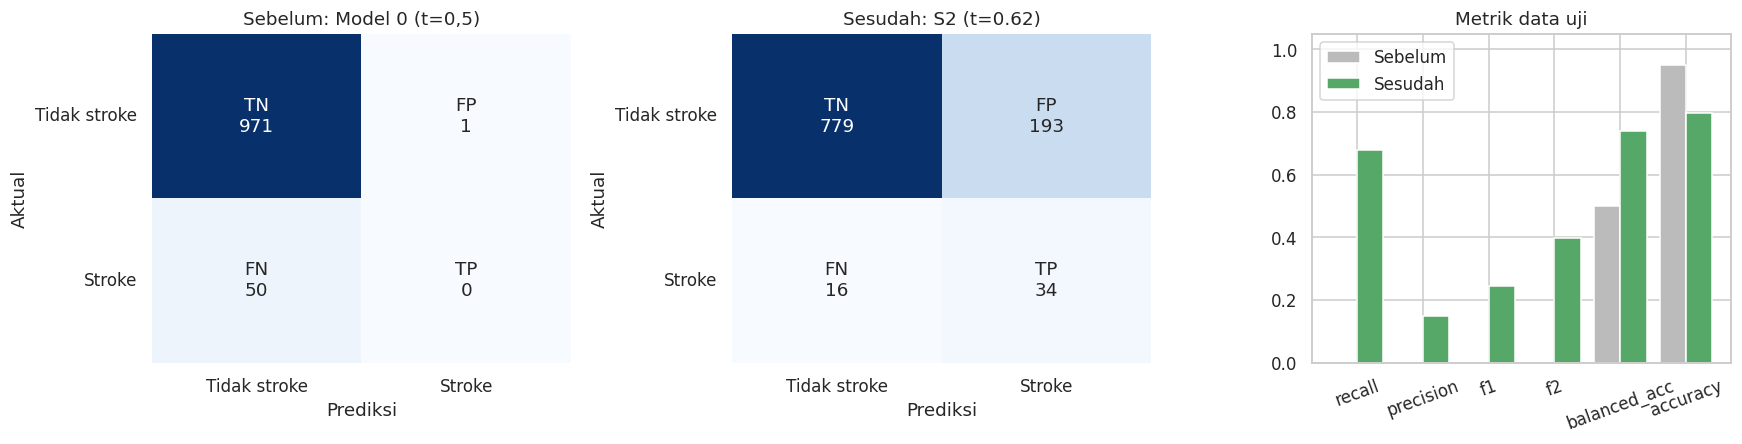

In [27]:
final_prep = Preprocessor(use_missing_flag=False).fit(df_train)
Xtr_f, Xte_f = final_prep.transform(df_train), final_prep.transform(df_test)
final_model = LogisticRegressionScratch(lr=0.3, epochs=3000, class_weight=True, threshold=t_best).fit(Xtr_f, y_train)

score_test = final_model.predict_proba(Xte_f)
res_final = metrics(y_test, final_model.predict(Xte_f), score_test)
compare = pd.DataFrame([res_0, res_final], index=['Sebelum (Model 0)', f'Sesudah (S2, t={t_best:.2f})'])
display(compare[['accuracy', 'precision', 'recall', 'specificity', 'f1', 'f2', 'balanced_acc', 'roc_auc',
                 'TP', 'FP', 'FN', 'TN']].round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
plot_cm(confusion(y_test, model_0.predict(Xte_f)), 'Sebelum: Model 0 (t=0,5)', axes[0])
plot_cm(confusion(y_test, final_model.predict(Xte_f)), f'Sesudah: S2 (t={t_best:.2f})', axes[1])
keys = ['recall', 'precision', 'f1', 'f2', 'balanced_acc', 'accuracy']
xs = np.arange(len(keys))
axes[2].bar(xs - 0.2, [res_0[k] for k in keys], 0.4, label='Sebelum', color='#BBBBBB')
axes[2].bar(xs + 0.2, [res_final[k] for k in keys], 0.4, label='Sesudah', color='#55A868')
axes[2].set_xticks(xs); axes[2].set_xticklabels(keys, rotation=20); axes[2].set_ylim(0, 1.05)
axes[2].set_title('Metrik data uji'); axes[2].legend()
plt.tight_layout(); plt.show()

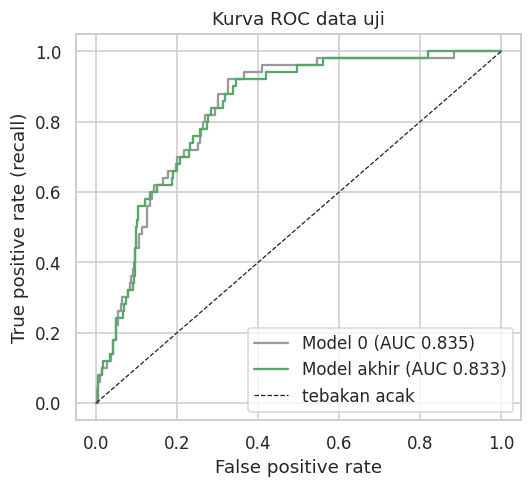

In [28]:
# Kurva ROC manual (TPR vs FPR untuk semua ambang)
def roc_curve(y, s):
    ts = np.r_[np.inf, np.sort(np.unique(s))[::-1]]
    tpr = [np.mean(s[y == 1] >= t) for t in ts]; fpr = [np.mean(s[y == 0] >= t) for t in ts]
    return np.array(fpr), np.array(tpr)
fpr0, tpr0 = roc_curve(y_test, model_0.predict_proba(Xte_f)); fpr1, tpr1 = roc_curve(y_test, score_test)
plt.figure(figsize=(5, 4.6))
plt.plot(fpr0, tpr0, label=f'Model 0 (AUC {res_0["roc_auc"]:.3f})', c='#999999')
plt.plot(fpr1, tpr1, label=f'Model akhir (AUC {res_final["roc_auc"]:.3f})', c='#55A868')
plt.plot([0, 1], [0, 1], 'k--', lw=.8, label='tebakan acak')
plt.xlabel('False positive rate'); plt.ylabel('True positive rate (recall)'); plt.title('Kurva ROC data uji')
plt.legend(); plt.tight_layout(); plt.show()

**Analisis sebelum vs sesudah**
- Accuracy **turun** — dan itu disengaja: accuracy tinggi pada Model 0 hanya karena selalu menebak kelas mayoritas.
- Recall naik dari **0** menjadi ±0,7: sebagian besar pasien stroke kini terdeteksi. F1, F2, dan balanced accuracy semuanya naik signifikan.
- AUC kedua model hampir sama: perbaikan terbesar bukan pada kemampuan *mengurutkan* risiko, tetapi pada **cara mengambil keputusan** (bobot kelas + ambang). Ini pesan utama Modul C.
- Precision ±0,15 berarti dari ±7 orang yang ditandai berisiko, ±1 benar stroke. Untuk alat **skrining awal** ini masih masuk akal (base rate hanya 5%, jadi kelompok yang ditandai ±3× lebih berisiko daripada rata-rata), tetapi model ini tidak cocok untuk keputusan diagnosis.
- Hasil di data uji (recall 0,68, F2 0,40) dekat dengan perkiraan CV (recall 0,70, F2 0,42) → pemilihan ambang lewat CV tidak overfit dan estimasinya bisa dipercaya.

In [29]:
# Analisis kesalahan: seperti apa pasien stroke yang terlewat (FN)?
pred_f = final_model.predict(Xte_f)
err = df_test.assign(skor=score_test, pred=pred_f)
fn_rows, tp_rows = err[(err.stroke == 1) & (err.pred == 0)], err[(err.stroke == 1) & (err.pred == 1)]
print(f'FN = {len(fn_rows)}, TP = {len(tp_rows)}')
display(pd.DataFrame({'FN (terlewat)': fn_rows[NUM_COLS + BIN_COLS].mean(),
                      'TP (terdeteksi)': tp_rows[NUM_COLS + BIN_COLS].mean()}).round(2))

FN = 16, TP = 34


,FN (terlewat),TP (terdeteksi)
age,54.88,74.82
avg_glucose_level,92.82,139.09
bmi,29.05,29.62
hypertension,0.00,0.26
heart_disease,0.00,0.35


**Pola kesalahan.** Pasien stroke yang terlewat rata-rata **jauh lebih muda** dan jarang punya hipertensi/penyakit jantung — profil yang memang "terlihat sehat" di data. Model linear dengan fitur ini tidak punya informasi untuk menangkap mereka. Perbaikan berikutnya yang realistis: fitur klinis tambahan (riwayat keluarga, kolesterol, tekanan darah numerik), bukan sekadar mengganti algoritma.

In [30]:
# Koreksi prior: model dilatih dengan class weight sehingga skornya "dibesarkan".
# logit_asli ≈ logit_model - log(w_pos/w_neg). Dipakai GUI untuk menampilkan perkiraan peluang yang realistis.
log_ratio = math.log(final_model.class_weight_ratio)
p_cal = 1 / (1 + np.exp(-(np.log(score_test / (1 - score_test)) - log_ratio)))
print(f'Rasio bobot kelas w1/w0 = {final_model.class_weight_ratio:.1f}')
print(f'Rata-rata skor mentah = {score_test.mean():.3f} | rata-rata peluang terkoreksi = {p_cal.mean():.3f} '
      f'| tingkat stroke aktual uji = {y_test.mean():.3f}')

Rasio bobot kelas w1/w0 = 19.5
Rata-rata skor mentah = 0.333 | rata-rata peluang terkoreksi = 0.052 | tingkat stroke aktual uji = 0.049


## C.5 Menyimpan model akhir (JSON) untuk Modul D

Saya memilih **JSON** daripada pickle: isinya bisa dibaca manusia (juri bisa membuka dan melihat bobotnya), tidak bergantung versi Python/class, dan aman dibuka (pickle dapat mengeksekusi kode saat di-load). Yang disimpan bukan hanya bobot, tetapi **seluruh parameter preprocessing** — tanpa itu, GUI tidak bisa mengubah input mentah menjadi fitur yang sama persis.

In [31]:
train_range = {c: [float(df_train[c].min()), float(df_train[c].max())] for c in NUM_COLS}
model_cfg = {
    'model': 'LogisticRegressionScratch', 'version': '1.0',
    'weights': final_model.w.tolist(), 'bias': float(final_model.b), 'threshold': t_best,
    'class_weight_ratio': float(final_model.class_weight_ratio), 'base_rate': float(y_train.mean()),
    'hyperparameters': {'lr': final_model.lr, 'epochs': final_model.epochs, 'l2': final_model.l2, 'class_weight': True},
    'preprocessing': final_prep.to_dict(), 'train_range': train_range,
    'test_metrics': {k: float(v) for k, v in res_final.items()},
}
with open('model_stroke.json', 'w', encoding='utf-8') as f:
    json.dump(model_cfg, f, indent=2)

with open('model_stroke.json', encoding='utf-8') as f:     # muat ulang & verifikasi
    loaded = json.load(f)
z = Xte_f @ np.array(loaded['weights']) + loaded['bias']
assert np.allclose(1 / (1 + np.exp(-z)), score_test), 'Model hasil load berbeda!'
print('model_stroke.json tersimpan & terverifikasi (', os.path.getsize('model_stroke.json'), 'byte )')

model_stroke.json tersimpan & terverifikasi ( 2910 byte )


---
# Modul D — Uji Coba Data Baru (GUI Tkinter)
Program GUI ada di file terpisah **`gui_stroke.py`**. Jalankan dengan: `python gui_stroke.py` (file `model_stroke.json` harus satu folder).

**Desain program**
| Bagian | Isi |
|---|---|
| `validate_inputs()` | validasi semua input **tanpa widget**: angka (menerima koma desimal), batas wajar, kolom wajib, cek konsistensi logika, peringatan bila di luar rentang data latih |
| `hitung_bmi()` | kalkulator BMI dari berat & tinggi untuk pengguna awam |
| `StrokePredictor` | memuat JSON → preprocessing identik dengan notebook → skor, kategori, perkiraan peluang, faktor risiko terbesar |
| `StrokeApp` | Tkinter: `Combobox` *readonly* untuk kategori (pengguna tidak bisa mengetik kategori asing), `Entry` untuk angka, tombol Prediksi/Reset/Contoh, `messagebox` untuk error |

**Agar tidak crash:** semua konversi angka lewat `try/except`; input salah → `messagebox` + prediksi dibatalkan; file model hilang/rusak → pesan error + tombol Prediksi dinonaktifkan; jaring pengaman `try/except` di callback.

**Ramah pengguna awam:** label Bahasa Indonesia, hasil berupa kategori berwarna ("RISIKO TINGGI/RENDAH"), perkiraan peluang dibandingkan rata-rata, 3 faktor yang paling menaikkan risiko, dan disclaimer bukan diagnosis medis.

Dua sel berikut **membuktikan** GUI memakai model yang sama dan tahan input salah (diuji tanpa membuka jendela).

In [32]:
from gui_stroke import StrokePredictor, validate_inputs, hitung_bmi

predictor = StrokePredictor.from_json('model_stroke.json')
gui_scores = np.array([predictor.predict(r)['skor'] for r in df_test.drop(columns=TARGET).to_dict('records')])
gui_scores_nan = np.array([predictor.predict({k: (None if (isinstance(v, float) and np.isnan(v)) else v)
                                              for k, v in r.items()})['skor']
                           for r in df_test.drop(columns=TARGET).to_dict('records')])
print('Selisih maksimum skor notebook vs GUI:', np.abs(gui_scores - score_test).max())
assert np.allclose(gui_scores, score_test) and np.allclose(gui_scores_nan, score_test)
print('Konsisten: GUI menghasilkan prediksi identik untuk seluruh', len(df_test), 'baris data uji.')

Selisih maksimum skor notebook vs GUI: 2.220446049250313e-16
Konsisten: GUI menghasilkan prediksi identik untuk seluruh 1022 baris data uji.


In [33]:
valid = {'gender': 'Laki-laki', 'age': '72', 'hypertension': 'Ya', 'heart_disease': 'Ya', 'ever_married': 'Ya',
         'work_type': 'Wiraswasta', 'Residence_type': 'Perkotaan', 'avg_glucose_level': '210', 'bmi': '31,5',
         'smoking_status': 'Pernah merokok (sudah berhenti)'}
uji = {
    'input valid (koma desimal)': {},
    'usia berupa huruf':          {'age': 'tujuh puluh'},
    'usia negatif':               {'age': '-5'},
    'usia kosong':                {'age': ''},
    'glukosa tidak wajar':        {'avg_glucose_level': '5000'},
    'BMI kosong (boleh)':         {'bmi': ''},
    'kategori tidak dipilih':     {'gender': ''},
    'kategori asing':             {'work_type': 'Astronot'},
    'nilai NaN':                  {'avg_glucose_level': 'nan'},
    'tidak konsisten (anak 40th)':{'age': '40', 'work_type': 'Anak-anak (belum bekerja)'},
    'di luar rentang latih':      {'age': '105'},
}
hasil = []
for nama, ubah in uji.items():
    raw = {**valid, **ubah}
    rec, errs, warns = validate_inputs(raw, model_cfg['train_range'])
    out = predictor.predict(rec) if rec else None
    hasil.append({'skenario': nama, 'status': 'DITOLAK' if errs else 'DIPREDIKSI',
                  'pesan': '; '.join(errs + warns)[:90],
                  'hasil': ('-' if out is None else ('RISIKO TINGGI' if out['label'] else 'RISIKO RENDAH')
                            + f" ({out['peluang']:.1%})")})
print('Kalkulator BMI 70 kg / 170 cm ->', hitung_bmi('70', '170'), '| huruf ->', hitung_bmi('abc', '170'))
pd.DataFrame(hasil)

Kalkulator BMI 70 kg / 170 cm -> (24.2, None) | huruf -> (None, 'Berat badan harus berupa angka (contoh: 45 atau 27.5).')


,skenario,status,pesan,hasil
0,input valid (koma desimal),DIPREDIKSI,,RISIKO TINGGI (33.5%)
1,usia berupa huruf,DITOLAK,Usia harus berupa angka (contoh: 45 atau 27.5).,-
2,usia negatif,DITOLAK,Usia harus di antara 0 dan 120.,-
3,usia kosong,DITOLAK,Usia wajib diisi.,-
4,glukosa tidak wajar,DITOLAK,Kadar glukosa harus di antara 20 dan 600.,-
5,BMI kosong (boleh),DIPREDIKSI,BMI kosong: model memakai nilai median data la...,RISIKO TINGGI (32.4%)
6,kategori tidak dipilih,DITOLAK,Pilih jenis kelamin dari daftar.,-
7,kategori asing,DITOLAK,Pilih jenis pekerjaan dari daftar.,-
8,nilai NaN,DITOLAK,Kadar glukosa tidak valid.,-
9,tidak konsisten (anak 40th),DIPREDIKSI,Usia >= 17 tahun tetapi pekerjaan 'Anak-anak'....,RISIKO TINGGI (8.9%)


Semua skenario input salah ditangani dengan pesan yang jelas — tidak ada yang menimbulkan exception.

---
# Kesimpulan
1. **Data:** 5.109 pasien, stroke hanya 4,9%. Missing BMI tidak acak, outlier BMI dibatasi, `Unknown` diperlakukan sebagai kategori. Semua statistik preprocessing dihitung dari data latih saja.
2. **Model:** logistic regression dari nol, gradient terverifikasi secara numerik, loss konvergen, koefisien sesuai insight EDA.
3. **Evaluasi:** accuracy 95% pada baseline adalah ilusi (recall 0). Dengan class weight dan ambang yang dipilih lewat 5-fold CV, recall naik menjadi ±0,7 dan F2 naik signifikan pada data uji yang hanya dipakai sekali.
4. **GUI:** memakai model dan preprocessing yang identik (terbukti), menolak input salah tanpa crash, dan menampilkan hasil yang dapat dipahami orang awam.

**Keterbatasan & langkah berikutnya:** precision masih rendah (data tidak terpisah jelas); data uji hanya ±50 kasus stroke sehingga metrik punya ketidakpastian ±0,1; model linear tidak menangkap interaksi (mis. usia × hipertensi) — bisa diuji dengan fitur interaksi atau Decision Tree (algoritma LKS Provinsi).